In [92]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [93]:

DATA_PATH = "/content/online_shoppers_intention.csv"
from pathlib import Path

dataset_path = Path(DATA_PATH)


In [94]:
df = pd.read_csv(DATA_PATH)



In [95]:
df.head(10)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.000000,0.100000,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.050000,0.140000,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.020000,0.050000,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False
5,0,0.0,0,0.0,19,154.216667,0.015789,0.024561,0.0,0.0,Feb,2,2,1,3,Returning_Visitor,False,False
6,0,0.0,0,0.0,1,0.000000,0.200000,0.200000,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
7,1,0.0,0,0.0,0,0.000000,0.200000,0.200000,0.0,0.0,Feb,1,2,1,5,Returning_Visitor,True,False
8,0,0.0,0,0.0,2,37.000000,0.000000,0.100000,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False
9,0,0.0,0,0.0,3,738.000000,0.000000,0.022222,0.0,0.4,Feb,2,4,1,2,Returning_Visitor,False,False


In [96]:
 df.shape


(12330, 18)

In [97]:
total_columns = df.shape[1]
target_column = "Revenue"

if target_column in df.columns:
    predictor_count = total_columns - 1
    print(f"Total columns     : {total_columns}")
    print(f"Predictor columns  : {predictor_count}")
    print(f"Target column      : {target_column}")
else:
    print(f"ERROR: Target column '{target_column}' not found.")


Total columns     : 18
Predictor columns  : 17
Target column      : Revenue


In [98]:
df.columns.to_list()

['Administrative',
 'Administrative_Duration',
 'Informational',
 'Informational_Duration',
 'ProductRelated',
 'ProductRelated_Duration',
 'BounceRates',
 'ExitRates',
 'PageValues',
 'SpecialDay',
 'Month',
 'OperatingSystems',
 'Browser',
 'Region',
 'TrafficType',
 'VisitorType',
 'Weekend',
 'Revenue']

In [99]:
df.dtypes

,0
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64


In [100]:
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

target_feature = "Revenue"

In [101]:
print("Numerical feature count   :", len(numerical_features))
print("Categorical feature count :", len(categorical_features))
print("Target feature count      : 1")
print("Total predictor count     :", len(numerical_features) + len(categorical_features))
print("Total column count        :", len(numerical_features) + len(categorical_features) + 1)

Numerical feature count   : 10
Categorical feature count : 7
Target feature count      : 1
Total predictor count     : 17
Total column count        : 18


In [102]:


df.isna().sum()



,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [103]:
df.columns.duplicated()



array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False])

In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [105]:
df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


In [106]:
df[categorical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
OperatingSystems,12330.0,2.124006,0.911325,1.0,2.0,2.0,3.0,8.0
Browser,12330.0,2.357097,1.717277,1.0,2.0,2.0,2.0,13.0
Region,12330.0,3.147364,2.401591,1.0,1.0,3.0,4.0,9.0
TrafficType,12330.0,4.069586,4.025169,1.0,2.0,2.0,4.0,20.0


In [107]:
print("Target column:", target_feature)
print("Target dtype :", df[target_feature].dtype)
print("Target values:", df[target_feature].unique())

Target column: Revenue
Target dtype : bool
Target values: [False  True]


In [108]:
target_classes = df[target_feature].unique()

print("Number of target classes:", len(target_classes))
print("Target classes:", target_classes)

Number of target classes: 2
Target classes: [False  True]


In [109]:
print(df[target_feature].value_counts())

Revenue
False    10422
True      1908
Name: count, dtype: int64


In [110]:
schema_table = pd.DataFrame({
    "Feature": numerical_features + categorical_features + [target_feature],
    "Role": (
        ["Predictor"] * len(numerical_features)
        + ["Predictor"] * len(categorical_features)
        + ["Target"]
    ),
    "Feature_Type": (
        ["Numerical"] * len(numerical_features)
        + ["Categorical"] * len(categorical_features)
        + ["Binary Categorical"]
    ),
    "Data_Type": [
        str(df[col].dtype)
        for col in numerical_features + categorical_features + [target_feature]
    ]
})

schema_table

,Feature,Role,Feature_Type,Data_Type
0,Administrative,Predictor,Numerical,int64
1,Administrative_Duration,Predictor,Numerical,float64
2,Informational,Predictor,Numerical,int64
3,Informational_Duration,Predictor,Numerical,float64
4,ProductRelated,Predictor,Numerical,int64
5,ProductRelated_Duration,Predictor,Numerical,float64
6,BounceRates,Predictor,Numerical,float64
7,ExitRates,Predictor,Numerical,float64
8,PageValues,Predictor,Numerical,float64
9,SpecialDay,Predictor,Numerical,float64


In [111]:
print("\nRevenue values:")

print(df["Revenue"].value_counts(dropna=False))

expected_labels = {True, False}
actual_labels = set(df["Revenue"].dropna().unique())
print("Target contains only expected Boolean labels:",
      actual_labels.issubset(expected_labels))


Revenue values:
Revenue
False    10422
True      1908
Name: count, dtype: int64
Target contains only expected Boolean labels: True


In [112]:
non_negative_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration"
]

negative_counts = (df[non_negative_columns] < 0).sum()

print("\nNegative values in page counts and durations:")
print(negative_counts)


Negative values in page counts and durations:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
dtype: int64


In [113]:
print("\nNumerical feature ranges:")
display(df[numerical_features].agg(["min", "max"]).T)


Numerical feature ranges:


,min,max
Administrative,0.0,27.000000
Administrative_Duration,0.0,3398.750000
Informational,0.0,24.000000
Informational_Duration,0.0,2549.375000
ProductRelated,0.0,705.000000
ProductRelated_Duration,0.0,63973.522230
BounceRates,0.0,0.200000
ExitRates,0.0,0.200000
PageValues,0.0,361.763742
SpecialDay,0.0,1.000000


In [114]:
# target distribution class
target_counts = df["Revenue"].value_counts().reindex(
    [False, True], fill_value=0
)

target_percentages = (
    df["Revenue"].value_counts(normalize=True)
    .reindex([False, True], fill_value=0) * 100
)

target_distribution = pd.DataFrame({
    "Class": ["No Purchase", "Purchase"],
    "Count": target_counts.values,
    "Percentage (%)": target_percentages.values.round(2)
})

display(target_distribution)

print("Total sessions:", len(df))

,Class,Count,Percentage (%)
0,No Purchase,10422,84.53
1,Purchase,1908,15.47


Total sessions: 12330


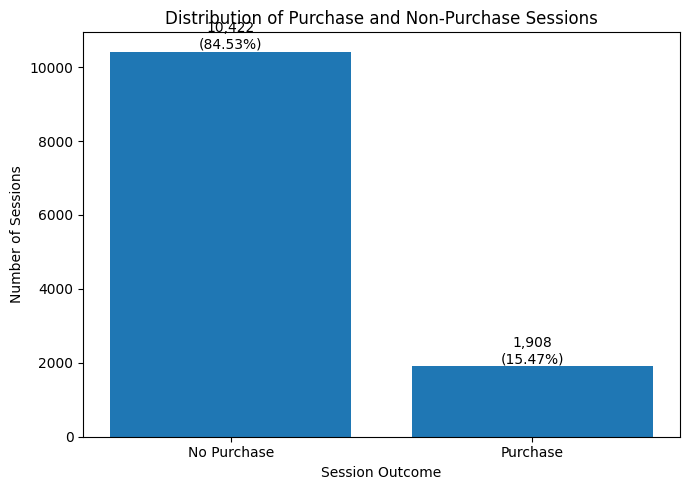

In [115]:
#visualisation
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

bars = plt.bar(
    target_distribution["Class"],
    target_distribution["Count"]
)

plt.title("Distribution of Purchase and Non-Purchase Sessions")
plt.xlabel("Session Outcome")
plt.ylabel("Number of Sessions")

for bar, count, percentage in zip(
    bars,
    target_distribution["Count"],
    target_distribution["Percentage (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [116]:
#compare majority and minority classes


majority_count = target_counts.max()
minority_count = target_counts.min()

imbalance_ratio = majority_count / minority_count

print("Majority class sessions:", majority_count)
print("Minority class sessions:", minority_count)
print(f"Majority-to-minority ratio: {imbalance_ratio:.2f}:1")

if imbalance_ratio >= 2:
    print("Interpretation: The target classes are imbalanced.")
else:
    print("Interpretation: The target classes are comparatively balanced.")

Majority class sessions: 10422
Minority class sessions: 1908
Majority-to-minority ratio: 5.46:1
Interpretation: The target classes are imbalanced.


###  Interpretation

The target distribution shows the proportion of online shopping sessions that resulted in purchases compared with sessions that did not.

- **No-purchase sessions:** [10422 and 84.53%]
- **Purchase sessions:** [1908 and 15.47%]
- **Majority-to-minority ratio:** [5.46:1]

The distribution indicates [whether the classes are imbalanced]. Therefore, accuracy alone may not adequately describe model performance. Precision, recall, F1-score, and ROC-AUC will also be considered during the model evaluation stage.

The results provide the baseline evidence for investigating class-imbalance handling techniques in the subsequent stage of the project.

In [117]:
# 4.1 Descriptive statistics of numerical features

numerical_summary = df[numerical_features].describe().T

numerical_summary["median"] = df[numerical_features].median()
numerical_summary["missing_values"] = df[numerical_features].isnull().sum()

display(numerical_summary.round(3))

,count,mean,std,min,25%,50%,75%,max,median,missing_values
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000,1.000,0
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750,7.500,0
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000,0.000,0
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375,0.000,0
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000,18.000,0
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522,598.937,0
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200,0.003,0
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200,0.025,0
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764,0.000,0
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000,0.000,0


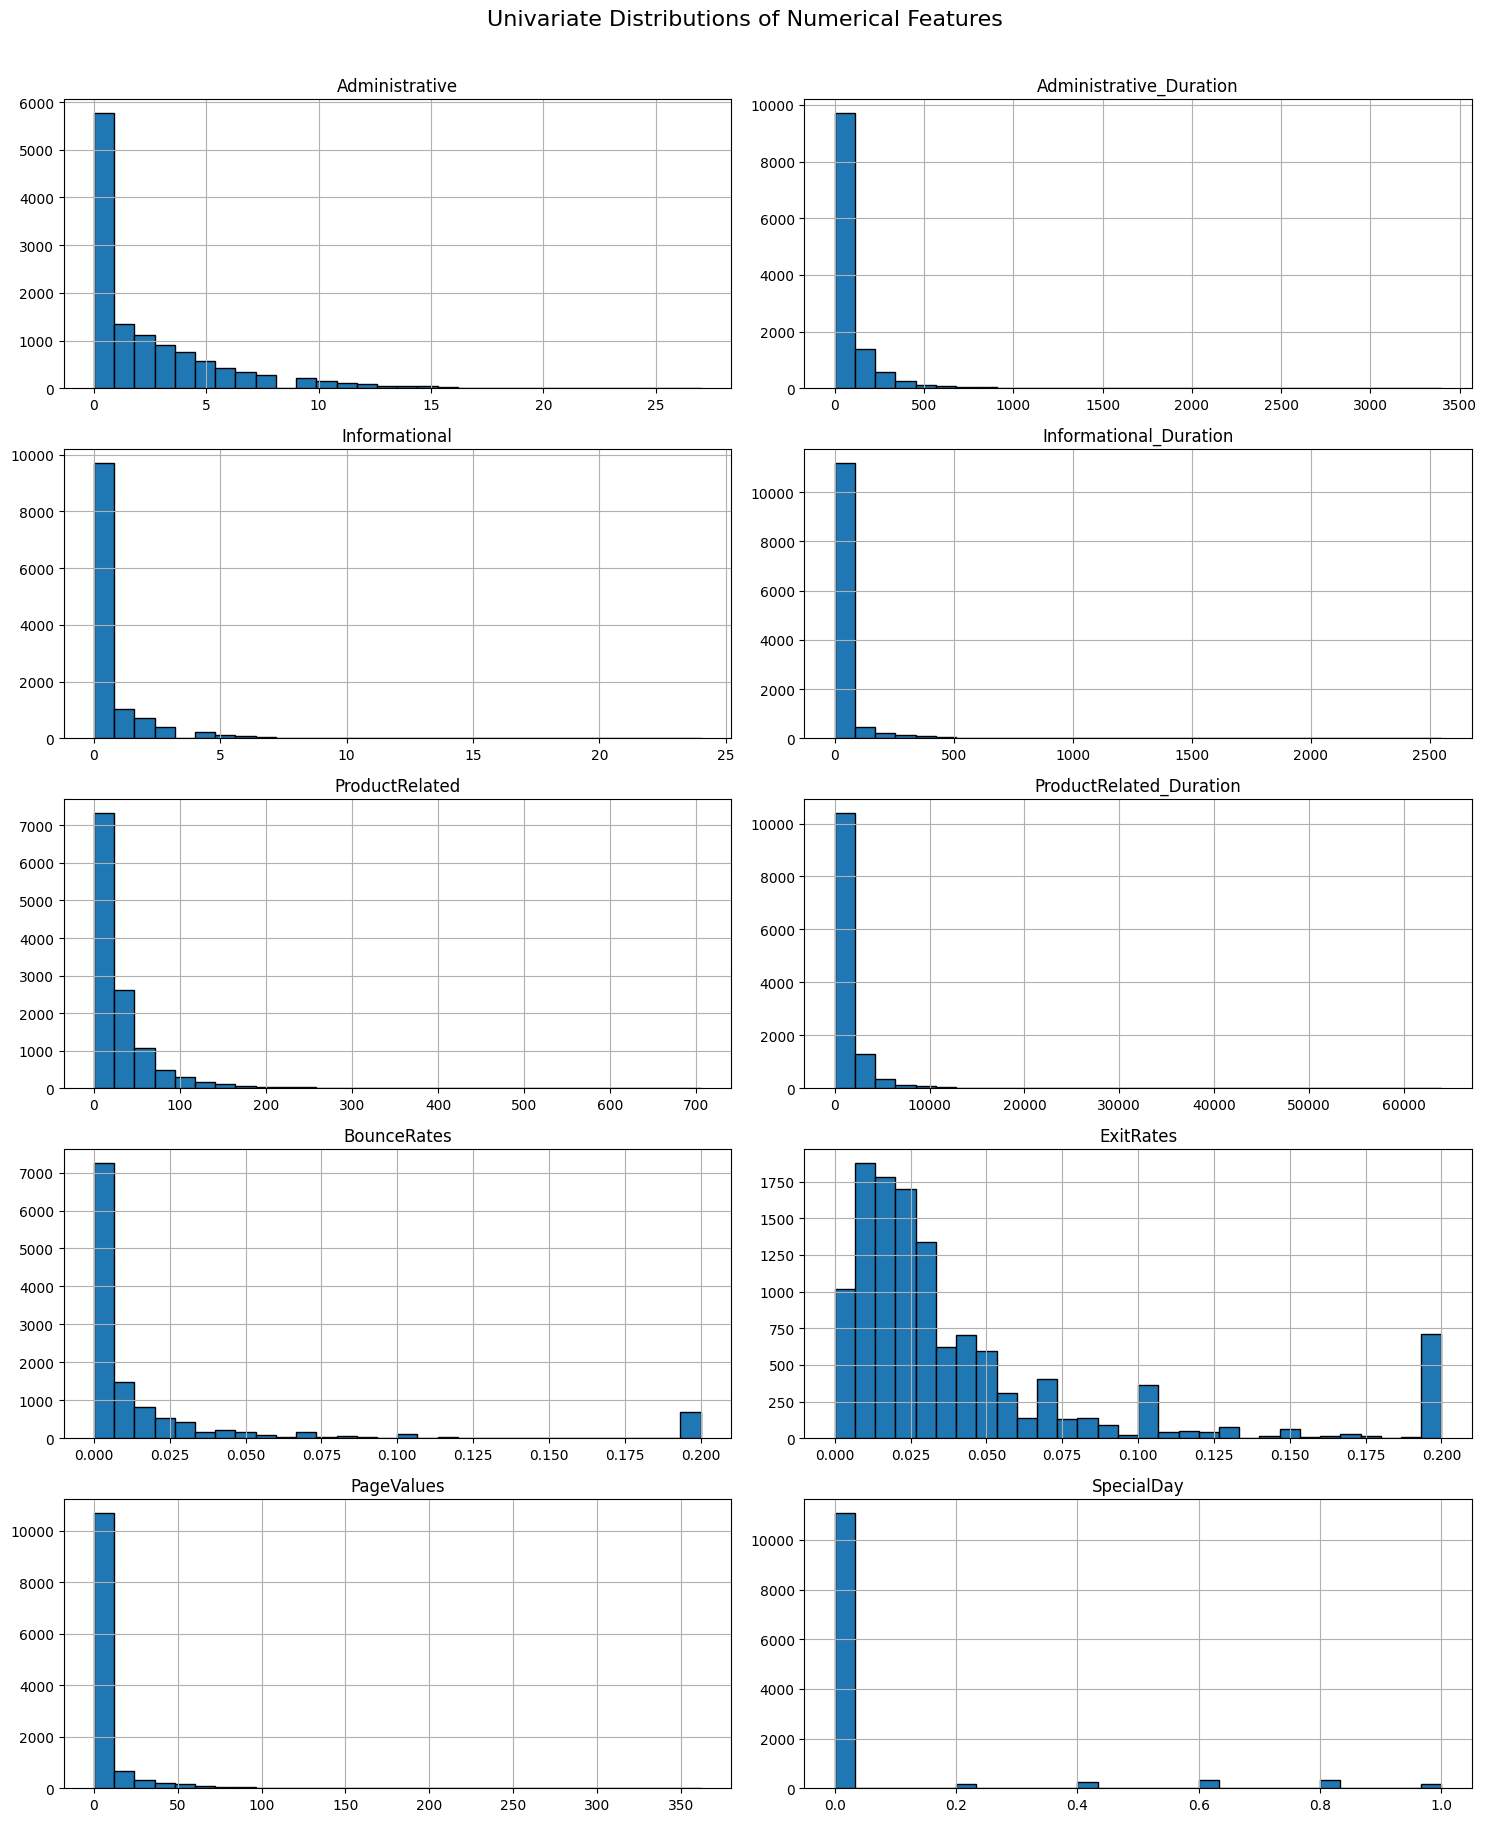

In [118]:
# 4.2 Histograms of all numerical features

import matplotlib.pyplot as plt

df[numerical_features].hist(
    bins=30,
    figsize=(15, 18),
    layout=(5, 2),
    edgecolor="black"
)

plt.suptitle(
    "Univariate Distributions of Numerical Features",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

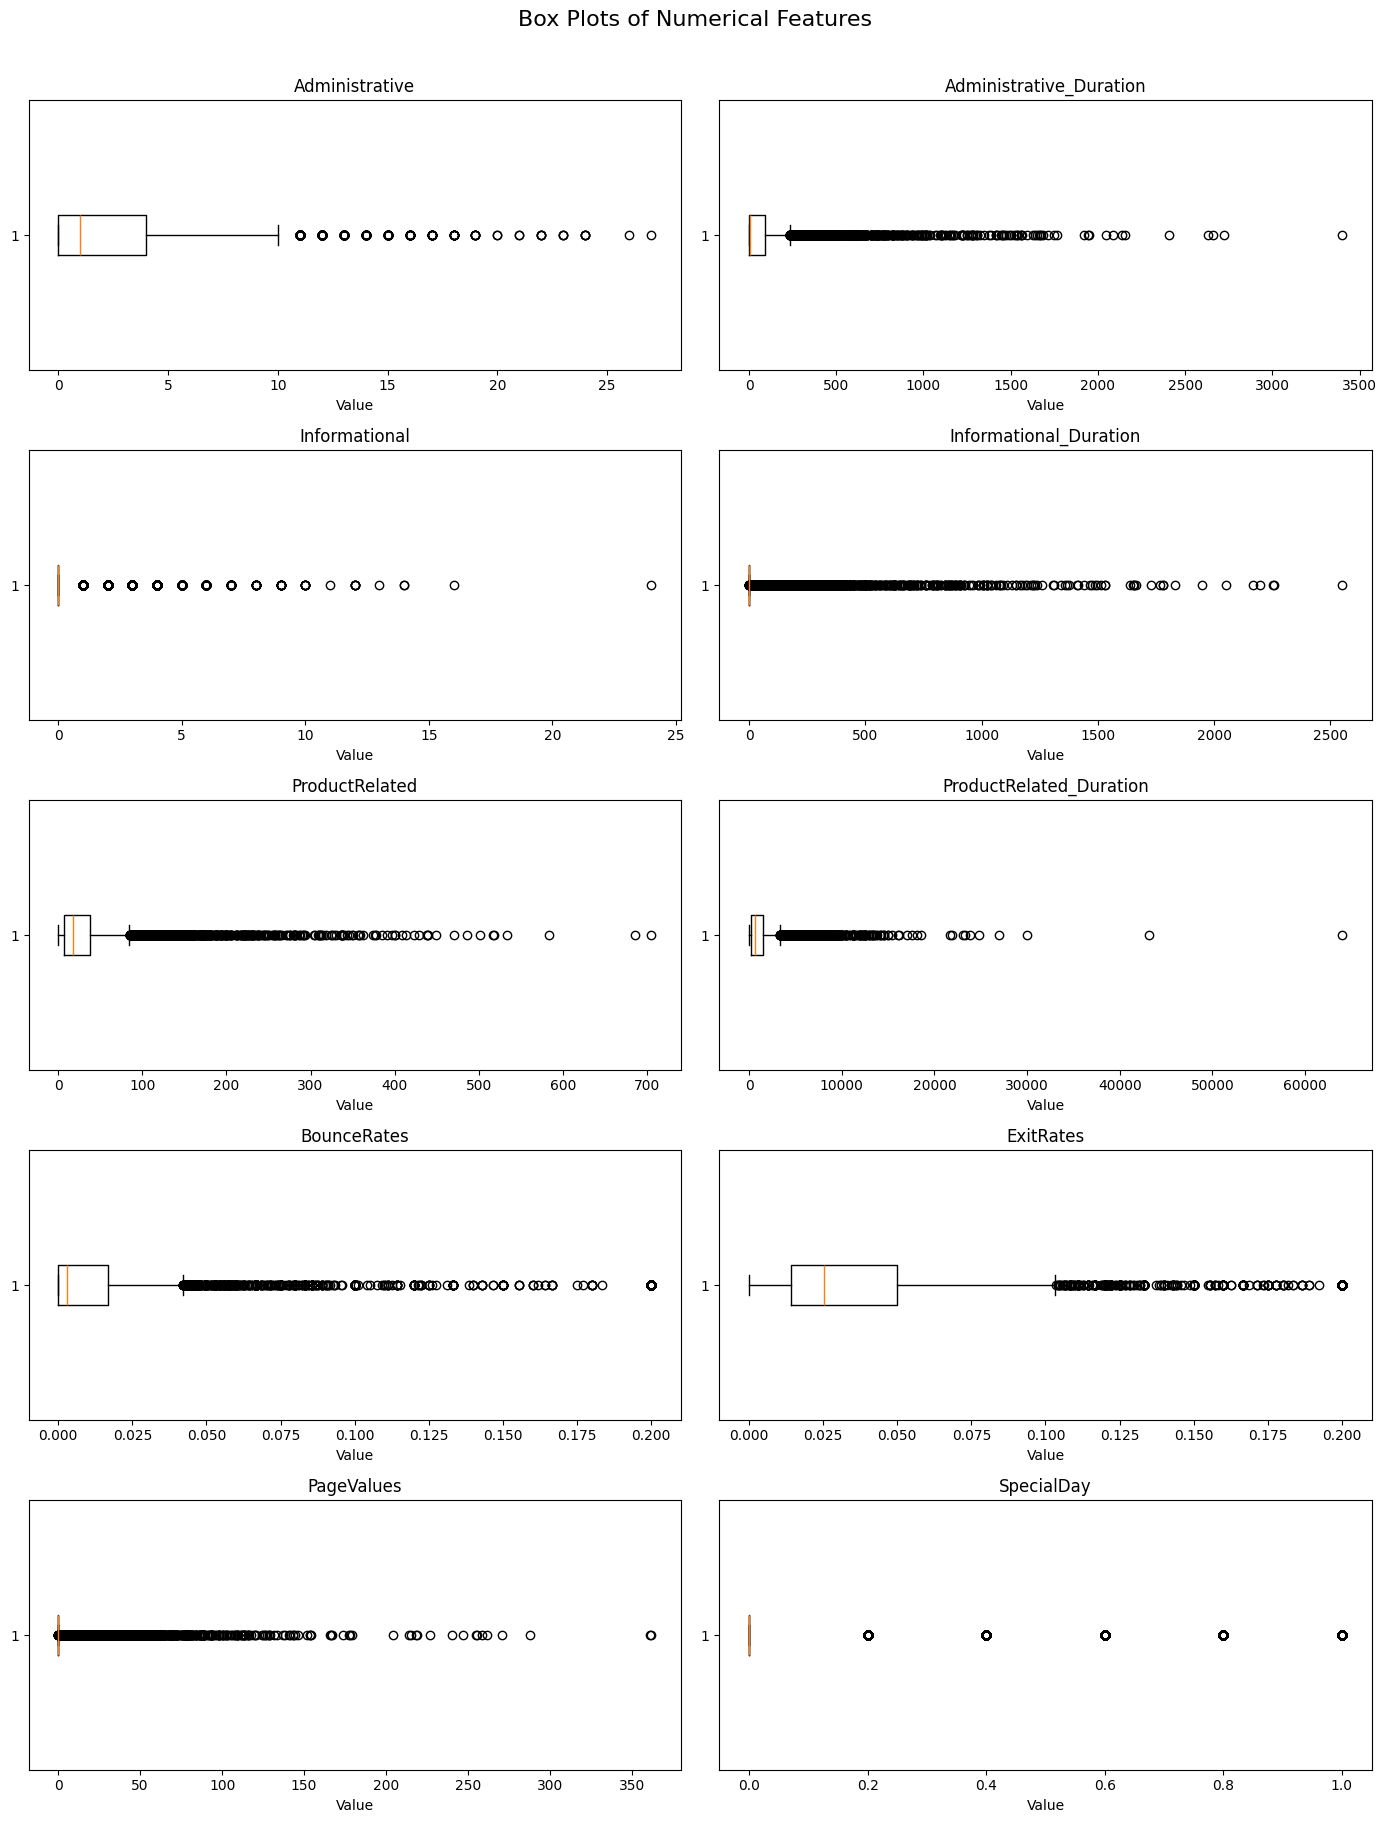

In [119]:
# 4.3 Box plots of numerical features

fig, axes = plt.subplots(
    nrows=5,
    ncols=2,
    figsize=(14, 18)
)

for ax, feature in zip(axes.flatten(), numerical_features):
    ax.boxplot(df[feature].dropna(), vert=False)
    ax.set_title(feature)
    ax.set_xlabel("Value")

plt.suptitle(
    "Box Plots of Numerical Features",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [120]:
# 4.4 Frequency tables of categorical features

for feature in categorical_features:
    print(f"\nFeature: {feature}")

    frequency_table = (
        df[feature]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    frequency_table["Percentage (%)"] = (
        frequency_table["Count"] / len(df) * 100
    ).round(2)

    display(frequency_table)


Feature: Month


,Category,Count,Percentage (%)
0,May,3364,27.28
1,Nov,2998,24.31
2,Mar,1907,15.47
3,Dec,1727,14.01
4,Oct,549,4.45
5,Sep,448,3.63
6,Aug,433,3.51
7,Jul,432,3.50
8,June,288,2.34
9,Feb,184,1.49



Feature: OperatingSystems


,Category,Count,Percentage (%)
0,2,6601,53.54
1,1,2585,20.97
2,3,2555,20.72
3,4,478,3.88
4,8,79,0.64
5,6,19,0.15
6,7,7,0.06
7,5,6,0.05



Feature: Browser


...

,Category,Count,Percentage (%)
0,2,3913,31.74
1,1,2451,19.88
2,3,2052,16.64
3,4,1069,8.67
4,13,738,5.99
5,10,450,3.65
6,6,444,3.60
7,8,343,2.78
8,5,260,2.11
9,11,247,2.00



Feature: VisitorType


,Category,Count,Percentage (%)
0,Returning_Visitor,10551,85.57
1,New_Visitor,1694,13.74
2,Other,85,0.69



Feature: Weekend


,Category,Count,Percentage (%)
0,False,9462,76.74
1,True,2868,23.26


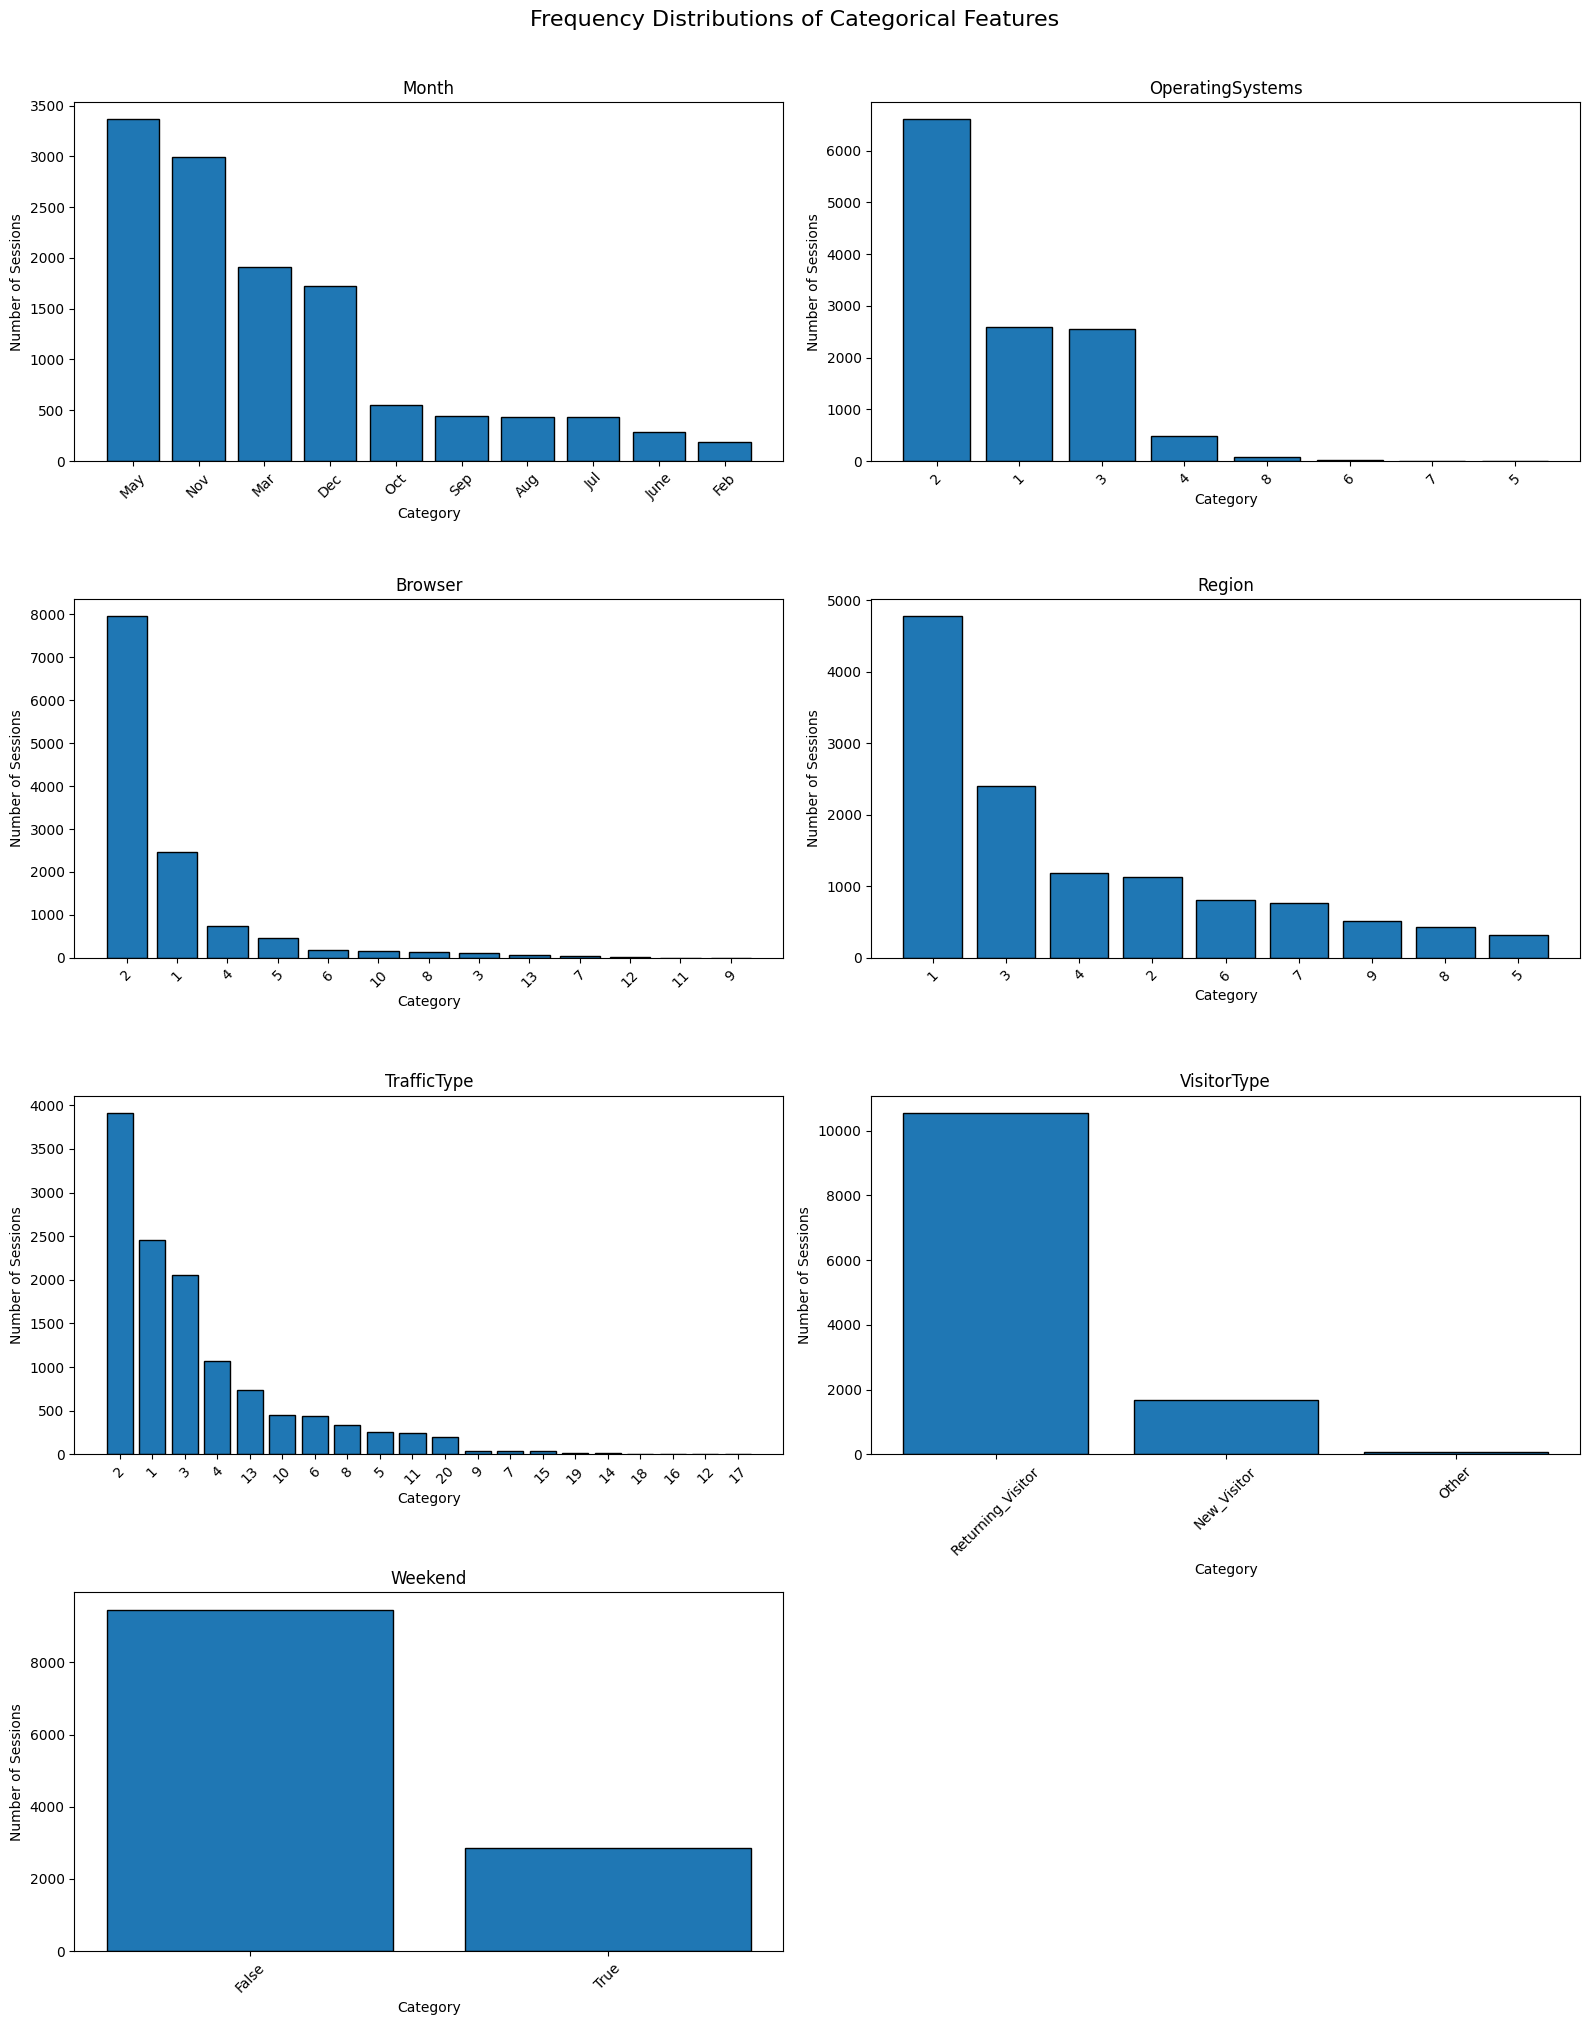

In [121]:
# 4.5 Bar charts of categorical features

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(16, 20)
)

for ax, feature in zip(axes.flatten(), categorical_features):
    counts = df[feature].value_counts(dropna=False)

    labels = [
        str(value) for value in counts.index
    ]

    ax.bar(labels, counts.values, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel("Category")
    ax.set_ylabel("Number of Sessions")
    ax.tick_params(axis="x", rotation=45)

# Hide the unused eighth subplot
for ax in axes.flatten()[len(categorical_features):]:
    ax.set_visible(False)

plt.suptitle(
    "Frequency Distributions of Categorical Features",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

### Interpretation of Univariate EDA

**Numerical distributions:** The numerical features show different patterns of distribution. The page-count features, including `Administrative`, `Informational`, and `ProductRelated`, are positively skewed, with most sessions involving relatively few page visits and fewer sessions involving a large number of visits. The duration features also show strong positive skewness, indicating that most sessions have shorter browsing durations while a smaller number have much longer durations. `BounceRates` and `ExitRates` are concentrated toward lower values, whereas `PageValues` contains many zero values and a smaller number of comparatively high values. `SpecialDay` is concentrated at zero, with fewer observations at higher values.

**Potential outliers:** The box plots identify potential outliers in several numerical features, particularly the duration features, page-count features, `PageValues`, `BounceRates`, and `ExitRates`. For example, `ProductRelated_Duration` reaches approximately 63,974, while `Administrative_Duration` reaches approximately 3,399. These observations extend well beyond the central ranges of their respective distributions. However, statistical outliers are not necessarily data errors, so they should not be removed without further investigation.

**Categorical distributions:** The categorical features show uneven frequencies across their categories. May accounts for the largest proportion of sessions in `Month` (27.28%), followed by November (24.31%). Operating system category 2 is the most frequent (53.54%), and browser category 2 accounts for 64.57% of sessions. Region category 1 represents the largest share of sessions (38.77%), while traffic type category 2 is the most frequent (31.74%). Most sessions belong to `Returning_Visitor` (85.57%), compared with `New_Visitor` (13.74%) and `Other` (0.69%). Additionally, 76.74% of sessions occurred on weekdays, while 23.26% occurred on weekends.

**Implications:** The strong skewness of several numerical features and the presence of potential outliers indicate that feature distributions should be considered during preprocessing and model development. The uneven frequencies of categorical values also show that some categories are much less common than others. These observations will inform subsequent feature analysis and preprocessing decisions. However, univariate analysis alone cannot establish which features are most useful for predicting purchases or whether rare categories are associated with higher or lower purchase rates. These relationships will be investigated in the next section.

Overall, the univariate EDA establishes the distributions and characteristics of the individual features. The next section examines how these features differ between purchase and non-purchase sessions.

In [122]:
# 5.1 Numerical features grouped by Revenue

numerical_comparison = df.groupby("Revenue")[numerical_features].median().T

numerical_comparison.columns = [
    "No Purchase (Median)",
    "Purchase (Median)"
]

display(numerical_comparison.round(3))

,No Purchase (Median),Purchase (Median)
Administrative,0.000,2.000
Administrative_Duration,0.000,52.367
Informational,0.000,0.000
Informational_Duration,0.000,0.000
ProductRelated,16.000,29.000
ProductRelated_Duration,510.190,1109.906
BounceRates,0.004,0.000
ExitRates,0.029,0.016
PageValues,0.000,16.758
SpecialDay,0.000,0.000


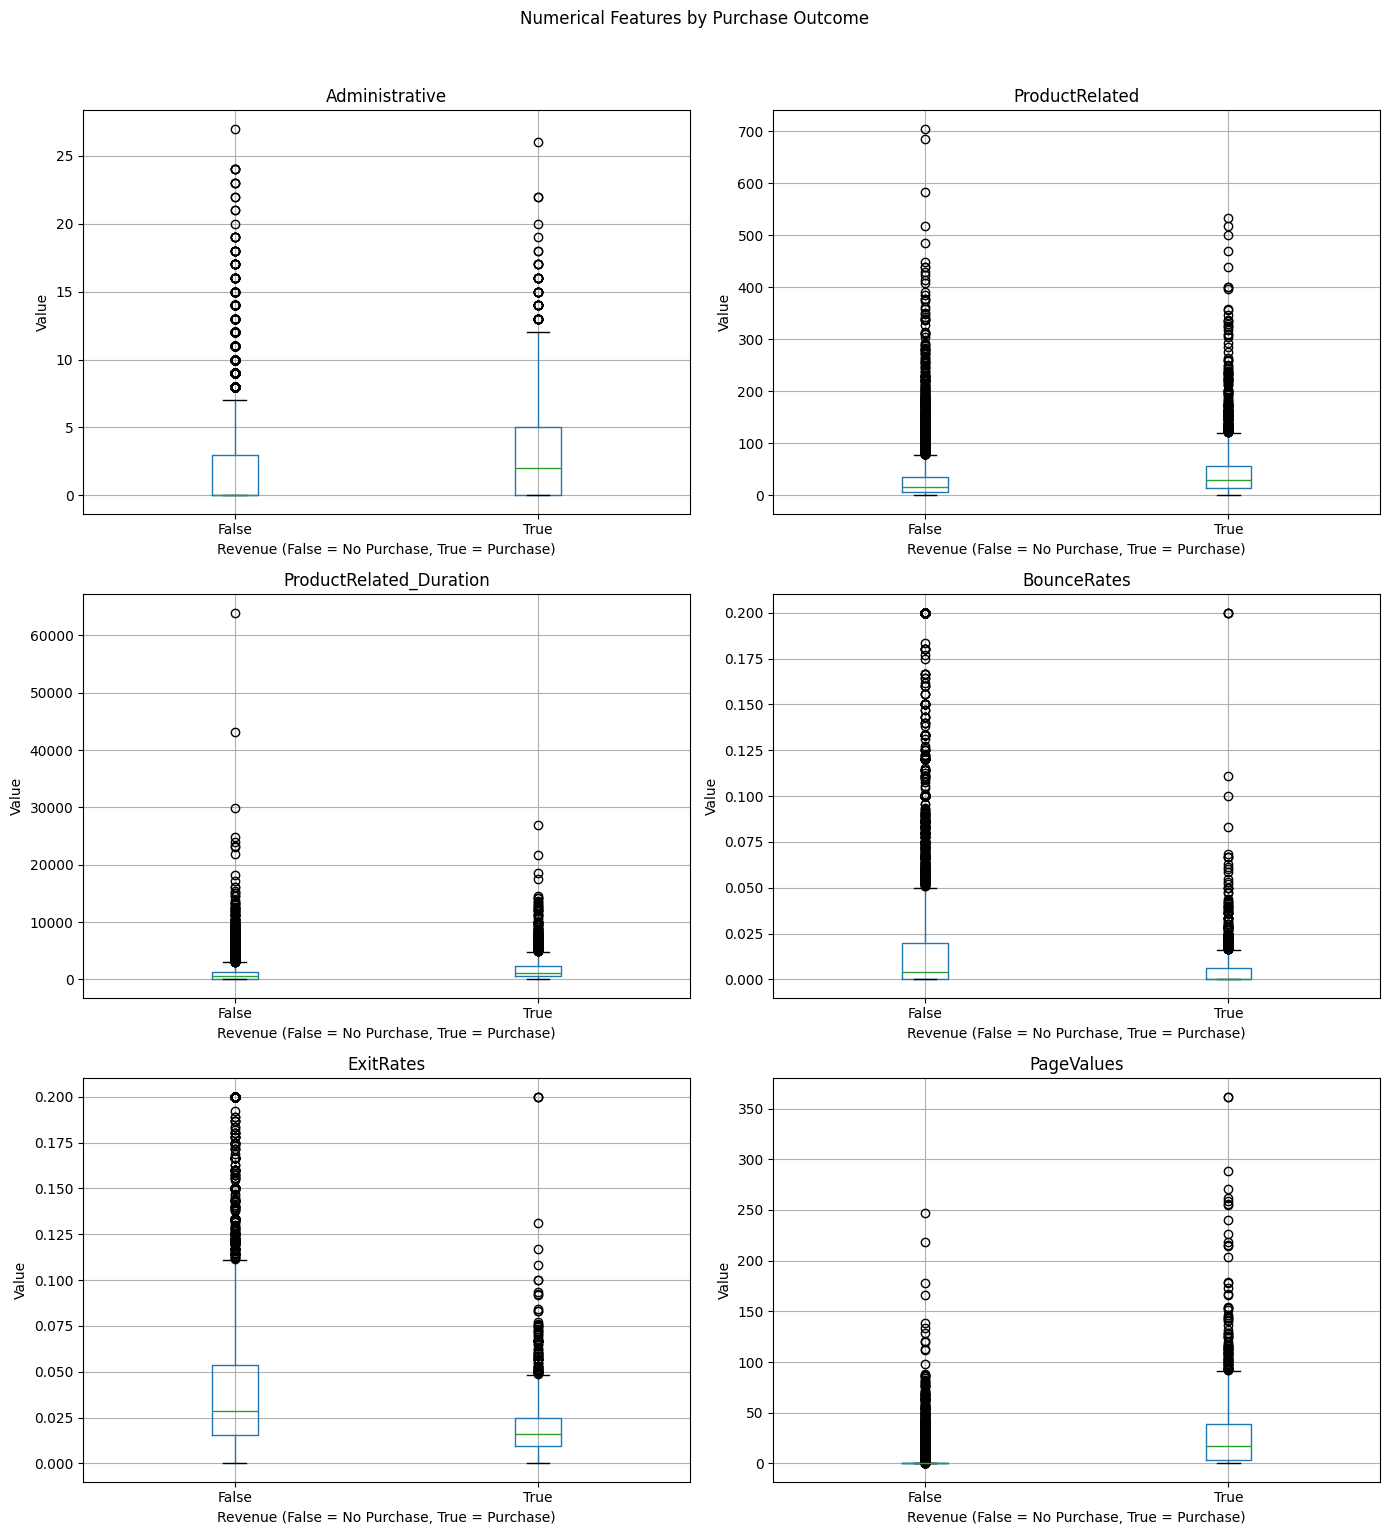

In [123]:
# 5.2 Compare numerical features across purchase outcomes

import matplotlib.pyplot as plt

selected_numerical = [
    "Administrative",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for ax, feature in zip(axes.flatten(), selected_numerical):
    df.boxplot(
        column=feature,
        by="Revenue",
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Revenue (False = No Purchase, True = Purchase)")
    ax.set_ylabel("Value")

plt.suptitle("Numerical Features by Purchase Outcome", y=1.02)
plt.tight_layout()
plt.show()

In [124]:
# 5.3 Purchase rates across selected categorical features

selected_categorical = [
    "Month",
    "VisitorType",
    "Weekend"
]

for feature in selected_categorical:
    purchase_rates = (
        df.groupby(feature, observed=False)["Revenue"]
        .agg(["mean", "count"])
        .rename(columns={
            "mean": "Purchase_Rate",
            "count": "Sessions"
        })
    )

    purchase_rates["Purchase_Rate (%)"] = (
        purchase_rates["Purchase_Rate"] * 100
    )

    purchase_rates = purchase_rates.sort_values(
        "Purchase_Rate (%)",
        ascending=False
    )

    print(f"\nPurchase rates by {feature}:")
    display(
        purchase_rates[["Sessions", "Purchase_Rate (%)"]].round(2)
    )


Purchase rates by Month:


,Sessions,Purchase_Rate (%)
Month,,
Nov,2998,25.35
Oct,549,20.95
Sep,448,19.20
Aug,433,17.55
Jul,432,15.28
Dec,1727,12.51
May,3364,10.85
June,288,10.07
Mar,1907,10.07



Purchase rates by VisitorType:


,Sessions,Purchase_Rate (%)
VisitorType,,
New_Visitor,1694,24.91
Other,85,18.82
Returning_Visitor,10551,13.93



Purchase rates by Weekend:


,Sessions,Purchase_Rate (%)
Weekend,,
True,2868,17.40
False,9462,14.89


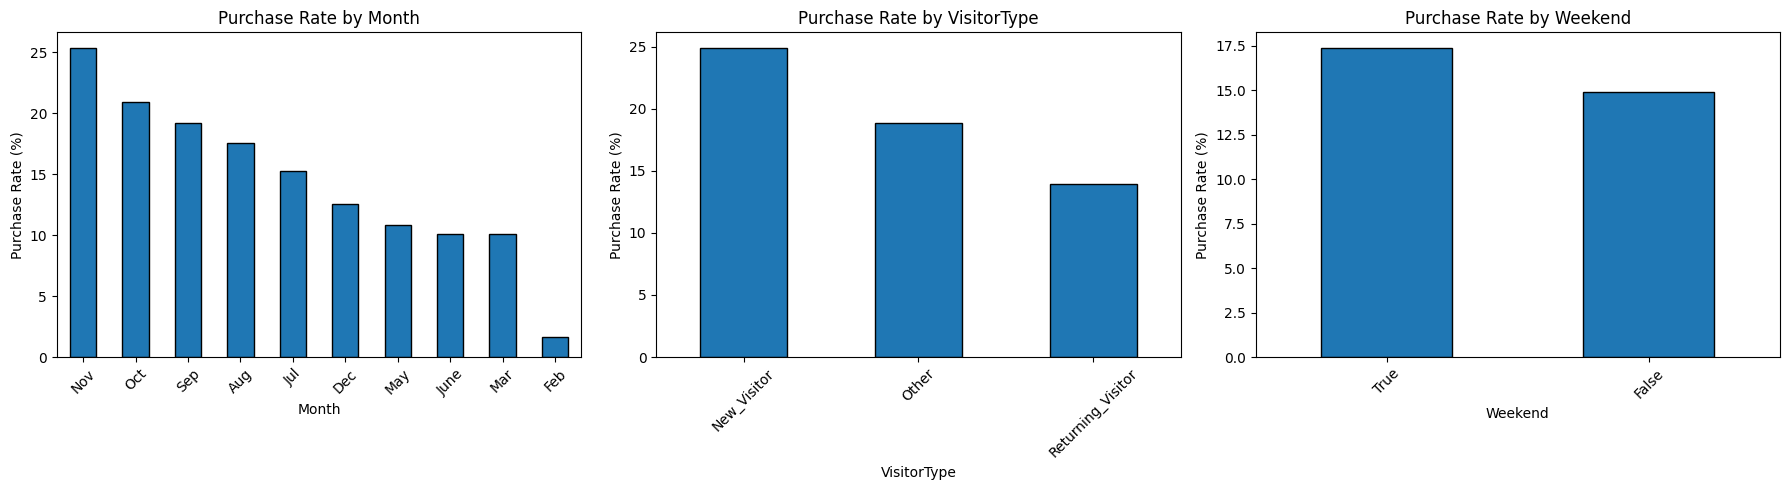

In [125]:
# 5.4 Plot purchase rates for selected categorical features

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, selected_categorical):
    rates = (
        df.groupby(feature, observed=False)["Revenue"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    rates.plot(kind="bar", ax=ax, edgecolor="black")

    ax.set_title(f"Purchase Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Purchase Rate (%)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Interpretation of Bivariate EDA

**Numerical features and purchase outcome:** The grouped median values and box plots reveal differences in browsing behaviour between purchase and non-purchase sessions. Sessions resulting in purchases have higher median values for `Administrative` (2 compared with 0), `Administrative_Duration` (52.367 compared with 0), `ProductRelated` (29 compared with 16), and `ProductRelated_Duration` (1109.906 compared with 510.190). This suggests that purchasing sessions are generally associated with more administrative and product-related browsing and longer product-page browsing durations. The median `Informational` and `Informational_Duration` values are zero for both groups, so their medians alone do not reveal a difference. Purchasers have lower median `BounceRates` (0 compared with 0.004) and `ExitRates` (0.016 compared with 0.029). The median `PageValues` is also higher for purchasers (16.758 compared with 0), making it a notable feature for further investigation.

**Categorical features and purchase rates:** Purchase rates differ across the selected categorical features. November has the highest observed purchase rate among the listed months at 25.35%, while February has the lowest at 1.63%. However, these months have different numbers of sessions, and February has only 184 sessions, so its rate should be interpreted cautiously. New visitors have a purchase rate of 24.91%, compared with 13.93% for returning visitors. The `Other` visitor category has a purchase rate of 18.82%, but contains only 85 sessions, making this estimate less reliable. Weekend sessions have a purchase rate of 17.40%, compared with 14.89% for weekday sessions. These results indicate that purchase rates vary with session month, visitor type, and weekend status.

**Implications for the project:** The observed differences suggest that browsing activity, page values, exit behaviour, visitor type, and session timing may be associated with purchase intention. In particular, `ProductRelated`, `ProductRelated_Duration`, `ExitRates`, and `PageValues` show notable differences between purchase and non-purchase sessions. However, these comparisons do not establish causation or prove which features will perform best in a predictive model. The role of `PageValues` should also be examined carefully to ensure that its information would be available at the intended prediction time. These observations will guide the subsequent feature-selection experiments, class-imbalance handling, and model evaluation.

In [126]:
# 6.1 Correlation matrix of numerical predictors

correlation_matrix = df[numerical_features].corr()

display(correlation_matrix.round(2))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
Administrative,1.00,0.60,0.38,0.26,0.43,0.37,-0.22,-0.32,0.10,-0.09
Administrative_Duration,0.60,1.00,0.30,0.24,0.29,0.36,-0.14,-0.21,0.07,-0.07
Informational,0.38,0.30,1.00,0.62,0.37,0.39,-0.12,-0.16,0.05,-0.05
Informational_Duration,0.26,0.24,0.62,1.00,0.28,0.35,-0.07,-0.11,0.03,-0.03
ProductRelated,0.43,0.29,0.37,0.28,1.00,0.86,-0.20,-0.29,0.06,-0.02
ProductRelated_Duration,0.37,0.36,0.39,0.35,0.86,1.00,-0.18,-0.25,0.05,-0.04
BounceRates,-0.22,-0.14,-0.12,-0.07,-0.20,-0.18,1.00,0.91,-0.12,0.07
ExitRates,-0.32,-0.21,-0.16,-0.11,-0.29,-0.25,0.91,1.00,-0.17,0.10
PageValues,0.10,0.07,0.05,0.03,0.06,0.05,-0.12,-0.17,1.00,-0.06
SpecialDay,-0.09,-0.07,-0.05,-0.03,-0.02,-0.04,0.07,0.10,-0.06,1.00


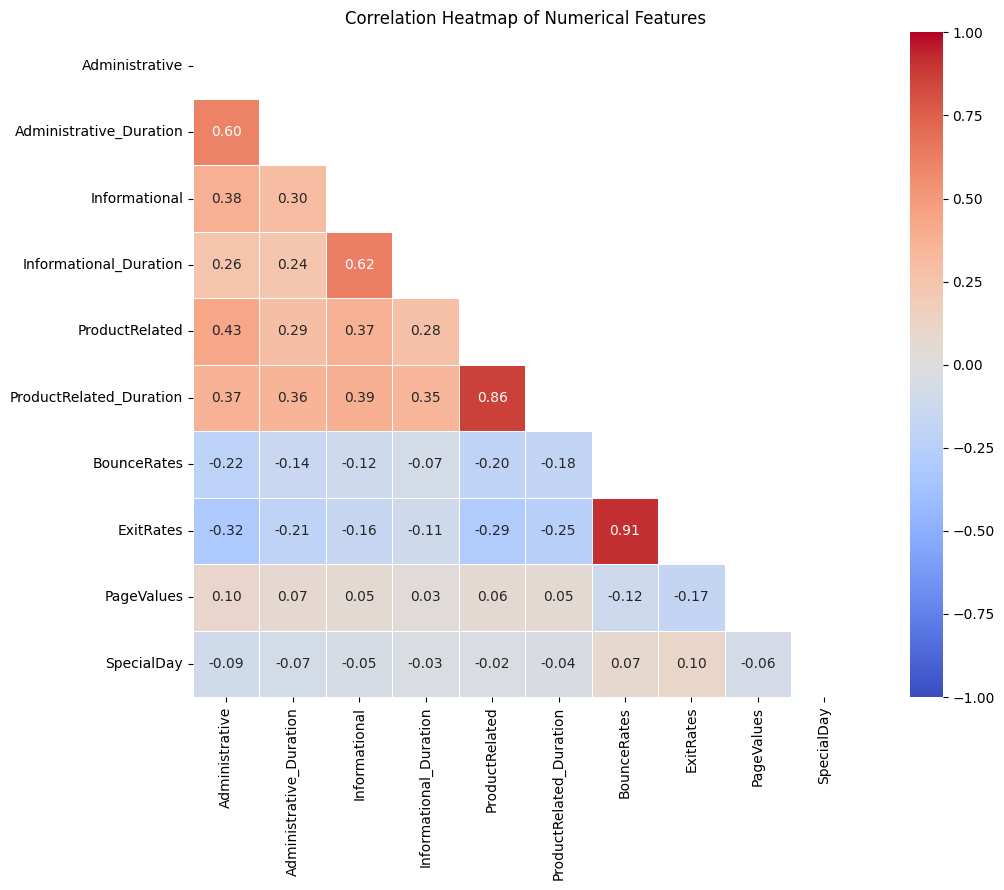

In [127]:
# 6.2 Correlation heatmap

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(12, 9))

mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool)
)

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [128]:
# Identify strongly correlated numerical feature pairs

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape, dtype=bool),
        k=1
    )
)

strong_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

strong_correlations.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

strong_correlations = (
    strong_correlations[
        strong_correlations["Correlation"].abs() >= 0.70
    ]
    .sort_values(
        by="Correlation",
        key=lambda values: values.abs(),
        ascending=False
    )
    .reset_index(drop=True)
)

if strong_correlations.empty:
    print("No numerical feature pairs have an absolute correlation of 0.70 or higher.")
else:
    display(strong_correlations.round(3))

,Feature_1,Feature_2,Correlation
0,BounceRates,ExitRates,0.913
1,ProductRelated,ProductRelated_Duration,0.861


###  Interpretation of Correlation Analysis

The correlation heatmap shows the strength and direction of linear relationships between the numerical predictor features.

**Strong positive correlations:** The strongest correlation is between `BounceRates` and `ExitRates`, with a correlation coefficient of **0.913**. This indicates a strong positive linear relationship between these two features. `ProductRelated` and `ProductRelated_Duration` also show a strong positive correlation of **0.861**, indicating that sessions with more product-related page visits tend to be associated with longer product-related browsing durations.

**Moderate correlations:** `Administrative` and `Administrative_Duration` have a positive correlation of **0.60**. Similarly, `Informational` and `Informational_Duration` have a correlation of **0.62**. These relationships suggest that visiting more pages within these categories tends to be associated with longer durations spent on them.

**Weak correlations:** Most other numerical feature pairs show weak to moderate correlations. For example, `PageValues` has relatively weak linear correlations with most numerical predictors, including `ProductRelated` (0.06) and `ProductRelated_Duration` (0.05). `SpecialDay` also shows weak correlations with the other features. These weak correlations do not necessarily mean that the features are unimportant for predicting purchase intention.

**Implications for feature selection:** The strong correlations between `BounceRates` and `ExitRates`, and between `ProductRelated` and `ProductRelated_Duration`, indicate potential redundancy within these feature pairs. These relationships should be considered during the subsequent feature-selection experiments. However, correlation alone is not sufficient reason to remove a feature, because each feature may contribute different information to a predictive model.

Overall, the correlation analysis identifies two strongly correlated feature pairs and several moderate relationships among browsing-related features. These findings provide useful background for the formal feature-selection and model-comparison stages of the project.

## 7. Key EDA Findings

The exploratory data analysis provides an understanding of the dataset's quality, feature distributions, purchase behaviour, and relationships between numerical predictors. The main findings are summarised below.

### 7.1 Data Quality

The dataset contains 12,330 online shopping sessions and 18 columns, comprising 17 predictor features and the target variable, `Revenue`. The data-quality checks examine missing values, duplicate records, target labels, negative page counts and durations, and numerical ranges. The results of these checks are used to determine whether any cleaning is necessary before preprocessing.

### 7.2 Target Distribution

The target variable distinguishes between sessions that resulted in a purchase and those that did not. The class distribution indicates that non-purchase sessions are more common than purchase sessions. This imbalance means that accuracy alone may not provide a complete assessment of model performance and supports evaluating additional metrics such as precision, recall, and F1-score.

### 7.3 Numerical Feature Distributions

Several numerical features, particularly browsing counts and duration measurements, exhibit positively skewed distributions. Box plots identify potential outliers in multiple numerical features. These observations should be considered during preprocessing, but potential outliers will not be removed without sufficient justification.

### 7.4 Relationships with Purchase Intention

The bivariate analysis shows differences between purchase and non-purchase sessions. Purchasers have higher median values for `Administrative`, `Administrative_Duration`, `ProductRelated`, `ProductRelated_Duration`, and `PageValues`, while their median `BounceRates` and `ExitRates` are lower. Purchase rates also vary across months, visitor types, and weekend status.

These observations suggest that browsing behaviour and session characteristics may be associated with purchase intention. Further experiments are required to determine their usefulness for prediction.

### 7.5 Correlation Between Numerical Features

The correlation analysis identifies two strongly correlated pairs: `BounceRates` and `ExitRates` (0.913), and `ProductRelated` and `ProductRelated_Duration` (0.861). These relationships suggest potential redundancy that can be investigated during feature selection. Other feature pairs generally exhibit weaker or moderate linear relationships.

### 7.6 Implications for the Proposed Methodology

The EDA findings motivate the subsequent investigation of feature selection, class-imbalance handling, and predictive model performance. The next stages will compare alternative approaches using consistent experimental procedures and appropriate evaluation metrics.

EDA provides preliminary observations rather than definitive evidence of predictive importance. The final conclusions will be based on the results of the model experiments.

In [129]:
# 8.1 Official stratified train/test split

from sklearn.model_selection import train_test_split
from pathlib import Path

# Separate predictors and target
X = df.drop(columns=["Revenue"]).copy()
y = df["Revenue"].copy()

# Official split: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Create output directories
project_root = Path("..")
results_dir = project_root / "results" / "taruni"
processed_dir = project_root / "data" / "processed"

results_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the raw split so the same rows can be reused
pd.concat([X_train, y_train.rename("Revenue")], axis=1).to_csv(
    processed_dir / "train_raw.csv", index=False
)

pd.concat([X_test, y_test.rename("Revenue")], axis=1).to_csv(
    processed_dir / "test_raw.csv", index=False
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training proportion:", round(len(X_train) / len(df), 3))
print("Testing proportion:", round(len(X_test) / len(df), 3))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(4))

print("\nOfficial split saved successfully.")

Training rows: 9864
Testing rows: 2466
Training proportion: 0.8
Testing proportion: 0.2

Training target distribution:
Revenue
False    0.8453
True     0.1547
Name: proportion, dtype: float64

Testing target distribution:
Revenue
False    0.8451
True     0.1549
Name: proportion, dtype: float64

Official split saved successfully.


In [130]:
import sklearn
print("scikit-learn version:", sklearn.__version__)

from sklearn.linear_model import LogisticRegression
print("scikit-learn import test passed.")

scikit-learn version: 1.6.1
scikit-learn import test passed.


In [131]:
#  Preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Use the feature groups already defined in your notebook
numerical_features = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

categorical_features = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

numerical_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

preprocessing_pipeline = ColumnTransformer(
    transformers=[
        ("numerical", numerical_transformer, numerical_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

# Fit ONLY on training data
processed_train = preprocessing_pipeline.fit_transform(X_train)

# Transform test data without fitting on it
processed_test = preprocessing_pipeline.transform(X_test)

feature_names = preprocessing_pipeline.get_feature_names_out()

print("Processed training shape:", processed_train.shape)
print("Processed testing shape:", processed_test.shape)
print("Number of processed features:", len(feature_names))
print("Training and testing feature dimensions match:",
      processed_train.shape[1] == processed_test.shape[1])

Processed training shape: (9864, 75)
Processed testing shape: (2466, 75)
Number of processed features: 75
Training and testing feature dimensions match: True


In [132]:
# 8.3 Save processed features and target labels

import numpy as np
from scipy import sparse

# Store the processed matrices efficiently
if sparse.issparse(processed_train):
    sparse.save_npz(
        processed_dir / "X_train_processed.npz",
        processed_train
    )
    sparse.save_npz(
        processed_dir / "X_test_processed.npz",
        processed_test
    )
else:
    np.save(processed_dir / "X_train_processed.npy", processed_train)
    np.save(processed_dir / "X_test_processed.npy", processed_test)

# Save labels separately
y_train.to_csv(processed_dir / "y_train.csv", index=False)
y_test.to_csv(processed_dir / "y_test.csv", index=False)

# Save processed feature names
pd.Series(feature_names, name="Feature").to_csv(
    processed_dir / "feature_names.csv",
    index=False
)

print("Processed features, labels, and feature names saved.")

Processed features, labels, and feature names saved.


In [133]:
# 8.4 Baseline model experiments

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "SVM": SVC(
        probability=True,
        random_state=42
    )
}

baseline_results = []
trained_baseline_models = {}

for model_name, model in baseline_models.items():
    print(f"Training {model_name}...")

    model.fit(processed_train, y_train)

    predictions = model.predict(processed_test)
    probabilities = model.predict_proba(processed_test)[:, 1]

    baseline_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    })

    trained_baseline_models[model_name] = model

baseline_results_df = pd.DataFrame(baseline_results)

display(
    baseline_results_df
    .set_index("Model")
    .round(4)
)

baseline_results_df.to_csv(
    results_dir / "baseline_model_results.csv",
    index=False
)

print("Baseline results saved.")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training SVM...


,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Model,,,,,
Logistic Regression,0.8808,0.7366,0.3586,0.4824,0.8828
Decision Tree,0.8585,0.5420,0.5576,0.5497,0.7356
Random Forest,0.8970,0.7712,0.4764,0.5890,0.9131
SVM,0.8873,0.7047,0.4686,0.5629,0.8824


Baseline results saved.



## Data Preprocessing, Exploratory Data Analysis and Baseline Model Evaluation

**Project Title:** Predicting Online Shopper Purchase Intention: A Study of Feature Selection and Class-Imbalance Handling on Model Performance and Interpretability


### 1. Project Overview

The objective of this phase is to prepare the Online Shoppers Purchasing Intention Dataset for machine-learning experiments, understand its characteristics through exploratory data analysis, and establish baseline classification performance. These baseline results provide a reference for evaluating the effects of feature selection and class-imbalance handling in subsequent experiments.

### 2. Dataset Description

The project uses the Online Shoppers Purchasing Intention Dataset from the UCI Machine Learning Repository.

- **Total observations:** 12,330
- **Total attributes:** 18
- **Predictor variables:** 17
- **Target variable:** `Revenue`
- **Problem type:** Binary classification

The target variable indicates whether an online browsing session resulted in a purchase (`True`) or did not result in a purchase (`False`).

**Dataset source:** https://archive.ics.uci.edu/dataset/468/online%2Bshoppers%2bpurchasing%2bintention%2bdataset

### 3. Exploratory Data Analysis

Exploratory data analysis was performed to understand the dataset's structure, feature distributions, target-class distribution and relationships among variables. The analysis included numerical summaries, categorical frequency distributions, purchase-rate comparisons, and correlation analysis.

The target distribution indicates a class imbalance: approximately 84.5% of sessions did not result in a purchase, compared with approximately 15.5% that resulted in a purchase.

The correlation analysis identified strong relationships between `BounceRates` and `ExitRates` (approximately 0.913), and between `ProductRelated` and `ProductRelated_Duration` (approximately 0.861). These findings provide a basis for investigating feature redundancy and feature-selection methods.

The analysis also examined how browsing activity and session characteristics varied between purchasing and non-purchasing sessions.

### 4. Data Splitting and Preprocessing

The dataset was divided into training and testing subsets using an 80:20 stratified split with `random_state=42`.

| Dataset | Number of observations |
|---|---:|
| Training set | 9,864 |
| Testing set | 2,466 |
| Total | 12,330 |

Stratification maintained similar target-class proportions across the two subsets.

The preprocessing pipeline applies numerical feature scaling and one-hot encoding to categorical variables. The resulting feature matrices contain 75 processed features.

| Processed dataset | Dimensions |
|---|---:|
| Training features | 9,864 × 75 |
| Testing features | 2,466 × 75 |

The training and testing matrices have matching feature dimensions, allowing consistent model evaluation.

### 5. Baseline Model Development

Four classification algorithms were evaluated using the preprocessed dataset:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)

The models were evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC. These metrics provide complementary measures of classification performance, particularly because the dataset contains substantially more non-purchasing sessions than purchasing sessions.

### 6. Baseline Experimental Results

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8808 | 0.7366 | 0.3586 | 0.4824 | 0.8828 |
| Decision Tree | 0.8585 | 0.5420 | 0.5576 | 0.5497 | 0.7356 |
| Random Forest | 0.8970 | 0.7712 | 0.4764 | 0.5890 | 0.9131 |
| SVM | 0.8873 | 0.7047 | 0.4686 | 0.5629 | 0.8824 |

### 7. Results and Discussion

Among the evaluated baseline models, Random Forest achieved the highest Accuracy (0.8970), Precision (0.7712), F1-score (0.5890) and ROC-AUC (0.9131). This indicates strong overall baseline performance among the four models under the reported evaluation settings.

The Decision Tree achieved the highest Recall (0.5576), indicating that it identified a larger proportion of actual purchasing sessions at the evaluated classification threshold. Logistic Regression achieved a relatively high ROC-AUC of 0.8828 but a lower Recall of 0.3586.

The results demonstrate that model performance differs depending on the evaluation metric. Because the target classes are imbalanced, Accuracy alone is not sufficient to assess the models' effectiveness in identifying purchasing sessions.

These experiments establish the baseline against which subsequent feature-selection and class-imbalance-handling approaches can be compared.

### 8. Conclusion and Next Phase

The dataset has been examined through exploratory data analysis, divided into stratified training and testing subsets, and transformed into a numerical feature representation. Baseline experiments were conducted using four classification algorithms, and their performance was compared using five evaluation metrics.

The baseline results indicate that Random Forest performs best on several reported metrics, while Decision Tree achieves the highest Recall.

The next phase of the project will investigate feature-selection techniques and class-imbalance-handling methods to determine whether they improve purchasing-session detection and overall model performance. Subsequent work will also examine model interpretability and compare the experimental results to identify an appropriate final model.


In [135]:
from pathlib import Path

spec_path = Path("../PIPELINE_SPEC.md")

spec_content = """# FML Project Pipeline Specification

## Project
Predicting Online Shopper Purchase Intention

## Dataset
UCI Online Shoppers Purchasing Intention Dataset

- Total observations: 12,330
- Target: Revenue
- Task: Binary classification

## Train-Test Split
- Training rows: 9,864
- Testing rows: 2,466
- Test size: 20%
- Random state: 42
- Stratification: Revenue

## Preprocessing
- Numerical features: StandardScaler
- Categorical features: OneHotEncoder
- One-hot encoding uses handle_unknown='ignore'
- Preprocessing must be fitted on training data only.
- Processed feature count: 75

## Baseline Models
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

## Baseline Results
See results/taruni/baseline_model_results.csv.

## Saved Artifacts
- data/processed/train_raw.csv
- data/processed/test_raw.csv
- data/processed/y_train.csv
- data/processed/y_test.csv
- data/processed/feature_names.csv
- results/taruni/baseline_model_results.csv
- results/taruni/preprocessing_pipeline.joblib

## Methodological Notes
- Preserve the official split for subsequent comparisons.
- Fit preprocessing and feature-selection steps using training data only.
- Apply resampling only to training data.
- Evaluate final experiments on the held-out test set.
- Examine PageValues for potential target leakage based on prediction-time availability.
"""

spec_path.write_text(spec_content, encoding="utf-8")
print("Created:", spec_path.resolve())
print("File exists:", spec_path.exists())

Created: /PIPELINE_SPEC.md
File exists: True


In [136]:
# 8.7 Verify the main handoff files

required_files = [
    processed_dir / "train_raw.csv",
    processed_dir / "test_raw.csv",
    processed_dir / "y_train.csv",
    processed_dir / "y_test.csv",
    processed_dir / "feature_names.csv",
    results_dir / "baseline_model_results.csv",
    results_dir / "preprocessing_pipeline.joblib",
    project_root / "PIPELINE_SPEC.md"
]

for file_path in required_files:
    print(
        "[OK]" if file_path.exists() else "[MISSING]",
        file_path
    )

print("\nBaseline models trained:", len(trained_baseline_models))
print("Processed training rows:", processed_train.shape[0])
print("Processed testing rows:", processed_test.shape[0])
print("Processed features:", len(feature_names))

[OK] ../data/processed/train_raw.csv
[OK] ../data/processed/test_raw.csv
[OK] ../data/processed/y_train.csv
[OK] ../data/processed/y_test.csv
[OK] ../data/processed/feature_names.csv
[OK] ../results/taruni/baseline_model_results.csv
[OK] ../results/taruni/preprocessing_pipeline.joblib
[OK] ../PIPELINE_SPEC.md

Baseline models trained: 4
Processed training rows: 9864
Processed testing rows: 2466
Processed features: 75


In [139]:
from pathlib import Path

spec_content = Path("/PIPELINE_SPEC.md").read_text(encoding="utf-8")

# Find the folder containing your notebook's data directory
candidates = [
    Path("/content"),
    Path("/content/FML"),
    Path("/content/drive/MyDrive/FML"),
]

project_root = next(
    (p for p in candidates if (p / "data" / "processed").is_dir()),
    None
)

if project_root is None:
    print("Project folder not found. Run the next diagnostic cell below.")
else:
    destination = project_root / "PIPELINE_SPEC.md"
    destination.write_text(spec_content, encoding="utf-8")
    print("Saved to:", destination)
    print("Exists:", destination.exists())

Project folder not found. Run the next diagnostic cell below.


In [138]:
from pathlib import Path

for p in Path("/content").rglob("train_raw.csv"):
    print("Found training file:", p)

In [140]:
from pathlib import Path

print("Current folder:", Path.cwd())
print("\nSearching for saved training files...")

for base in [Path("/content"), Path("/tmp")]:
    if base.exists():
        for p in base.rglob("train_raw.csv"):
            print("TRAIN FILE:", p)
        for p in base.rglob("baseline_model_results.csv"):
            print("RESULTS FILE:", p)

Current folder: /content

Searching for saved training files...


In [141]:
from pathlib import Path

for folder in [Path("/content/data"), Path("/data"), Path("/content/results"), Path("/results")]:
    if folder.exists():
        print(f"\nFOUND FOLDER: {folder}")
        for item in folder.rglob("*"):
            if item.is_file():
                print(item)


FOUND FOLDER: /data
/data/processed/y_test.csv
/data/processed/test_raw.csv
/data/processed/X_train_processed.npz
/data/processed/train_raw.csv
/data/processed/y_train.csv
/data/processed/feature_names.csv
/data/processed/X_test_processed.npz

FOUND FOLDER: /results
/results/taruni/preprocessing_pipeline.joblib
/results/taruni/baseline_model_results.csv


In [142]:
from pathlib import Path
import zipfile

data_dir = Path("/data/processed")
results_dir = Path("/results/taruni")
spec_source = Path("/PIPELINE_SPEC.md")

zip_path = Path("/content/taruni_handoff.zip")

files = [
    data_dir / "train_raw.csv",
    data_dir / "test_raw.csv",
    data_dir / "y_train.csv",
    data_dir / "y_test.csv",
    data_dir / "X_train_processed.npz",
    data_dir / "X_test_processed.npz",
    data_dir / "feature_names.csv",
    results_dir / "baseline_model_results.csv",
    results_dir / "preprocessing_pipeline.joblib",
]

missing = [str(p) for p in files if not p.exists()]
if missing:
    print("Missing files:")
    print("\n".join(missing))
else:
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for p in files:
            if p.parent == data_dir:
                arcname = f"data/processed/{p.name}"
            else:
                arcname = f"results/taruni/{p.name}"
            z.write(p, arcname)

        if spec_source.exists():
            z.write(spec_source, "PIPELINE_SPEC.md")

    print("ZIP created:", zip_path)
    print("Files included:", len(files) + int(spec_source.exists()))
    print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

ZIP created: /content/taruni_handoff.zip
Files included: 10
ZIP size (MB): 0.66


In [143]:
from google.colab import files
files.download("/content/taruni_handoff.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>